In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import spearmanr
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

plt.style.use("seaborn-v0_8")

df_planetas = pd.read_csv("../data_processed/03_catalogo_con_parametros_derivados.csv")
df_sistemas = pd.read_csv("../data_processed/05_sistemas_planetarios_enriquecido.csv")

print("Planetas:", df_planetas.shape)
print("Sistemas:", df_sistemas.shape)

Planetas: (6267, 44)
Sistemas: (615, 23)


In [4]:
df_candidatos = df_planetas[
    df_planetas["hostname"].notna() &
    df_planetas["pl_name"].notna() &
    df_planetas["pl_rade"].notna() &
    df_planetas["pl_orbper"].notna() &
    df_planetas["st_met"].notna() &
    df_planetas["st_mass"].notna() &
    (df_planetas["pl_rade"] >= 1.0) &
    (df_planetas["pl_rade"] <= 4.0) &
    (df_planetas["pl_orbper"] < 100)
].copy()

hosts_multi = df_sistemas["hostname"].unique()

df_multi = df_candidatos[
    df_candidatos["hostname"].isin(hosts_multi)
].copy()

print("Planetas candidatos en sistemas finales:", df_multi.shape)
print("Sistemas finales:", df_multi["hostname"].nunique())

Planetas candidatos en sistemas finales: (1513, 44)
Sistemas finales: 615


# 06 — Spacing vs uniformidad planetaria

## Objetivo

Evaluar si la separación orbital entre planetas adyacentes está asociada con su desigualdad de tamaños.

La variable principal de uniformidad se define como:

`U_R = |log(R_out / R_in)|`

donde valores mayores indican planetas adyacentes menos similares en radio.

In [5]:
pares_adyacentes = []

for hostname, grupo in df_multi.groupby("hostname"):
    grupo = grupo.sort_values("pl_orbper").copy()
    
    if len(grupo) < 2:
        continue
    
    periodos = grupo["pl_orbper"].values
    radios = grupo["pl_rade"].values
    nombres = grupo["pl_name"].values
    
    for i in range(len(grupo) - 1):
        P_in = periodos[i]
        P_out = periodos[i + 1]
        R_in = radios[i]
        R_out = radios[i + 1]
        
        pares_adyacentes.append({
            "hostname": hostname,
            "planeta_interior": nombres[i],
            "planeta_exterior": nombres[i + 1],
            "P_in": P_in,
            "P_out": P_out,
            "R_in": R_in,
            "R_out": R_out,
            "period_ratio": P_out / P_in,
            "log_period_ratio": np.log(P_out / P_in),
            "radius_ratio": R_out / R_in,
            "log_radius_ratio": np.log(R_out / R_in),
            "abs_log_radius_ratio": abs(np.log(R_out / R_in)),
            "outer_larger": int(R_out > R_in)
        })

df_pares = pd.DataFrame(pares_adyacentes)

print(df_pares.shape)
df_pares.head()

(898, 13)


,hostname,planeta_interior,planeta_exterior,P_in,P_out,R_in,R_out,period_ratio,log_period_ratio,radius_ratio,log_radius_ratio,abs_log_radius_ratio,outer_larger
0,55 Cnc B,55 Cnc B b,55 Cnc B c,6.799400,33.747000,1.69000,2.16,4.963232,1.602057,1.278107,0.245380,0.245380,1
1,AU Mic,AU Mic d,AU Mic c,12.735960,18.859023,1.02000,2.79,1.480770,0.392562,2.735294,1.006239,1.006239,1
2,CoRoT-7,CoRoT-7 b,CoRoT-7 c,0.853592,3.698000,1.68135,2.83,4.332282,1.466095,1.683171,0.520680,0.520680,1
3,DMPP-6,DMPP-6 b,DMPP-6 c,7.602700,36.441000,2.28000,3.74,4.793166,1.567191,1.640351,0.494910,0.494910,1
4,EPIC 206024342,EPIC 206024342 c,EPIC 206024342 b,0.911724,4.507560,1.40000,1.70,4.943996,1.598174,1.214286,0.194156,0.194156,1


In [6]:
cols_sistema_para_pares = [
    "hostname",
    "gapped",
    "st_met",
    "st_mass",
    "median_radius",
    "N_planetas",
    "compactness_proxy"
]

df_pares = df_pares.merge(
    df_sistemas[cols_sistema_para_pares],
    on="hostname",
    how="left"
)

df_pares["pair_median_radius"] = df_pares[["R_in", "R_out"]].median(axis=1)

print(df_pares.shape)
df_pares.head()

(898, 20)


,hostname,planeta_interior,planeta_exterior,P_in,P_out,R_in,R_out,period_ratio,log_period_ratio,radius_ratio,log_radius_ratio,abs_log_radius_ratio,outer_larger,gapped,st_met,st_mass,median_radius,N_planetas,compactness_proxy,pair_median_radius
0,55 Cnc B,55 Cnc B b,55 Cnc B c,6.799400,33.747000,1.69000,2.16,4.963232,1.602057,1.278107,0.245380,0.245380,1,0.0,0.160,0.2600,1.925000,2.0,0.624197,1.925000
1,AU Mic,AU Mic d,AU Mic c,12.735960,18.859023,1.02000,2.79,1.480770,0.392562,2.735294,1.006239,1.006239,1,0.0,0.120,0.5725,1.905000,2.0,2.547368,1.905000
2,CoRoT-7,CoRoT-7 b,CoRoT-7 c,0.853592,3.698000,1.68135,2.83,4.332282,1.466095,1.683171,0.520680,0.520680,1,0.0,0.055,0.8595,2.255675,2.0,0.682084,2.255675
3,DMPP-6,DMPP-6 b,DMPP-6 c,7.602700,36.441000,2.28000,3.74,4.793166,1.567191,1.640351,0.494910,0.494910,1,0.0,0.320,1.0790,3.010000,2.0,0.638084,3.010000
4,EPIC 206024342,EPIC 206024342 c,EPIC 206024342 b,0.911724,4.507560,1.40000,1.70,4.943996,1.598174,1.214286,0.194156,0.194156,1,0.0,-0.220,0.9280,1.700000,3.0,0.720282,1.550000


In [7]:
revision_pares = pd.DataFrame({
    "variable": [
        "log_period_ratio",
        "abs_log_radius_ratio",
        "st_met",
        "st_mass",
        "pair_median_radius",
        "N_planetas"
    ],
    "datos_disponibles": [
        df_pares["log_period_ratio"].notna().sum(),
        df_pares["abs_log_radius_ratio"].notna().sum(),
        df_pares["st_met"].notna().sum(),
        df_pares["st_mass"].notna().sum(),
        df_pares["pair_median_radius"].notna().sum(),
        df_pares["N_planetas"].notna().sum()
    ],
    "minimo": [
        df_pares["log_period_ratio"].min(),
        df_pares["abs_log_radius_ratio"].min(),
        df_pares["st_met"].min(),
        df_pares["st_mass"].min(),
        df_pares["pair_median_radius"].min(),
        df_pares["N_planetas"].min()
    ],
    "mediana": [
        df_pares["log_period_ratio"].median(),
        df_pares["abs_log_radius_ratio"].median(),
        df_pares["st_met"].median(),
        df_pares["st_mass"].median(),
        df_pares["pair_median_radius"].median(),
        df_pares["N_planetas"].median()
    ],
    "maximo": [
        df_pares["log_period_ratio"].max(),
        df_pares["abs_log_radius_ratio"].max(),
        df_pares["st_met"].max(),
        df_pares["st_mass"].max(),
        df_pares["pair_median_radius"].max(),
        df_pares["N_planetas"].max()
    ]
})

revision_pares.round(4)

,variable,datos_disponibles,minimo,mediana,maximo
0,log_period_ratio,898,0.0376,0.7729,3.9905
1,abs_log_radius_ratio,898,0.0000,0.2223,1.3015
2,st_met,898,-0.6100,-0.0100,0.4800
3,st_mass,898,0.0898,0.8752,1.6500
4,pair_median_radius,898,1.0350,2.0810,3.8050
5,N_planetas,898,2.0000,3.0000,6.0000


In [8]:
df_pares_modelo = df_pares[
    df_pares["log_period_ratio"].notna() &
    df_pares["abs_log_radius_ratio"].notna()
].copy()

rho_spacing_uniform, p_spacing_uniform = spearmanr(
    df_pares_modelo["log_period_ratio"],
    df_pares_modelo["abs_log_radius_ratio"]
)

# Bootstrap IC95% para Spearman rho
n_boot = 5000
rng = np.random.default_rng(42)

x = df_pares_modelo["log_period_ratio"].values
y = df_pares_modelo["abs_log_radius_ratio"].values
n = len(df_pares_modelo)

rho_boot = []

for _ in range(n_boot):
    idx = rng.integers(0, n, size=n)
    rho_i, _ = spearmanr(x[idx], y[idx])
    rho_boot.append(rho_i)

rho_boot = np.array(rho_boot)

rho_ci_low = np.percentile(rho_boot, 2.5)
rho_ci_high = np.percentile(rho_boot, 97.5)

print(f"N pares = {n}")
print(f"Spearman rho = {rho_spacing_uniform:.4f}")
print(f"p-value = {p_spacing_uniform:.4e}")
print(f"IC95% bootstrap = [{rho_ci_low:.4f}, {rho_ci_high:.4f}]")

N pares = 898
Spearman rho = 0.1826
p-value = 3.5888e-08
IC95% bootstrap = [0.1179, 0.2464]


In [9]:
tabla_spacing_uniformidad_spearman = pd.DataFrame({
    "analisis": ["log_period_ratio_vs_abs_log_radius_ratio"],
    "N_pares": [n],
    "spearman_rho": [rho_spacing_uniform],
    "p_value": [p_spacing_uniform],
    "rho_IC95_low": [rho_ci_low],
    "rho_IC95_high": [rho_ci_high],
    "n_bootstrap": [n_boot]
})

tabla_spacing_uniformidad_spearman.to_csv(
    "../tables/tabla_spacing_uniformidad_spearman_bootstrap.csv",
    index=False
)

tabla_spacing_uniformidad_spearman

,analisis,N_pares,spearman_rho,p_value,rho_IC95_low,rho_IC95_high,n_bootstrap
0,log_period_ratio_vs_abs_log_radius_ratio,898,0.182577,3.588791e-08,0.11795,0.24645,5000


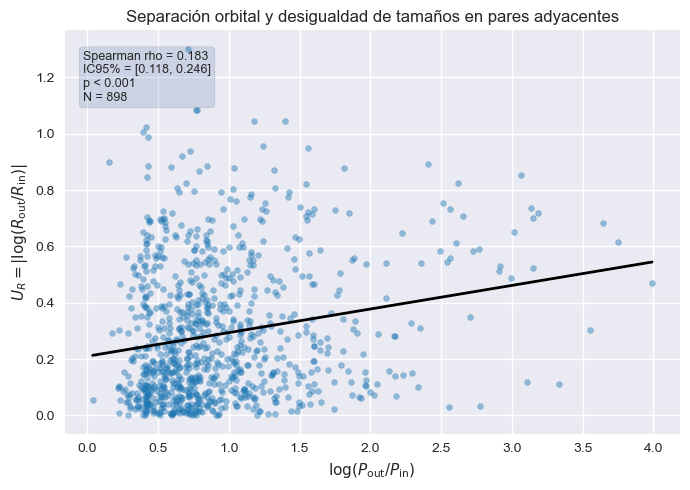

In [10]:
plt.figure(figsize=(7, 5))

plt.scatter(
    df_pares_modelo["log_period_ratio"],
    df_pares_modelo["abs_log_radius_ratio"],
    s=18,
    alpha=0.45,
    color="tab:blue"
)

coef = np.polyfit(
    df_pares_modelo["log_period_ratio"],
    df_pares_modelo["abs_log_radius_ratio"],
    1
)

x_line = np.linspace(
    df_pares_modelo["log_period_ratio"].min(),
    df_pares_modelo["log_period_ratio"].max(),
    100
)

y_line = coef[0] * x_line + coef[1]

plt.plot(
    x_line,
    y_line,
    color="black",
    linewidth=2
)

plt.xlabel(r"$\log(P_\mathrm{out}/P_\mathrm{in})$")
plt.ylabel(r"$U_R = |\log(R_\mathrm{out}/R_\mathrm{in})|$")
plt.title("Separación orbital y desigualdad de tamaños en pares adyacentes")

plt.text(
    0.03,
    0.95,
    f"Spearman rho = {rho_spacing_uniform:.3f}\nIC95% = [{rho_ci_low:.3f}, {rho_ci_high:.3f}]\np < 0.001\nN = {n}",
    transform=plt.gca().transAxes,
    va="top",
    fontsize=9,
    bbox=dict(boxstyle="round", alpha=0.2)
)

plt.tight_layout()
plt.savefig(
    "../figures/spacing_vs_radius_inequality.png",
    dpi=300
)

plt.show()

In [11]:
df_modelo_uniformidad = df_pares[
    df_pares["abs_log_radius_ratio"].notna() &
    df_pares["log_period_ratio"].notna() &
    df_pares["st_met"].notna() &
    df_pares["st_mass"].notna() &
    df_pares["pair_median_radius"].notna() &
    df_pares["N_planetas"].notna()
].copy()

X_uniformidad = df_modelo_uniformidad[
    [
        "log_period_ratio",
        "st_met",
        "st_mass",
        "pair_median_radius",
        "N_planetas"
    ]
]

X_uniformidad = sm.add_constant(X_uniformidad)

y_uniformidad = df_modelo_uniformidad["abs_log_radius_ratio"]

modelo_uniformidad_spacing = sm.OLS(
    y_uniformidad,
    X_uniformidad
).fit()

modelo_uniformidad_spacing.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                             OLS Regression Results                             
================================================================================
Dep. Variable:     abs_log_radius_ratio   R-squared:                       0.060
Model:                              OLS   Adj. R-squared:                  0.054
Method:                   Least Squares   F-statistic:                     11.32
Date:                  Mon, 17 Aug 2026   Prob (F-statistic):           1.32e-10
Time:                          09:25:58   Log-Likelihood:                 46.967
No. Observations:                   898   AIC:                            -81.93
Df Residuals:                       892   BIC:                            -53.13
Df Model:                             5                                         
Covariance Type:              nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  0.2333      0.048      4.829      0.000       0.138       0.328
log_period_ratio       0.0859      0.014      5.970      0.000       0.058       0.114
st_met                 0.1399      0.047      2.976      0.003       0.048       0.232
st_mass                0.0567      0.035      1.621      0.105      -0.012       0.125
pair_median_radius    -0.0352      0.014     -2.531      0.012      -0.062      -0.008
N_planetas             0.0012      0.008      0.152      0.879      -0.015       0.017
==============================================================================
Omnibus:                      102.911   Durbin-Watson:                   2.072
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              136.767
Skew:                           0.919   Prob(JB):                     2.00e-30
Kurtosis:                       3.525   Cond. No.                         30.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Los pares planetarios más separados orbitalmente presentan mayor desigualdad de tamaños, incluso al controlar por propiedades estelares y del sistema.

El modelo multivariable muestra que la separación orbital entre planetas adyacentes sigue siendo un predictor significativo de la desigualdad de tamaños. En particular, log(P_out/P_in) tiene un coeficiente positivo y significativo (coef = 0.086, IC95% = [0.058, 0.114], p < 0.001), lo que indica que pares más separados tienden a presentar planetas menos similares en radio. Esta relación persiste al controlar por [Fe/H], masa estelar, radio mediano del par y multiplicidad del sistema.

In [12]:
resumen_modelo_uniformidad_spacing = pd.DataFrame({
    "modelo": ["U_R ~ log_period_ratio + st_met + st_mass + pair_median_radius + N_planetas"],
    "N": [int(modelo_uniformidad_spacing.nobs)],
    "R2": [modelo_uniformidad_spacing.rsquared],
    "R2_ajustado": [modelo_uniformidad_spacing.rsquared_adj],
    "F_p_value": [modelo_uniformidad_spacing.f_pvalue],
    "AIC": [modelo_uniformidad_spacing.aic],
    "BIC": [modelo_uniformidad_spacing.bic]
})

resumen_modelo_uniformidad_spacing.to_csv(
    "../tables/resumen_modelo_uniformidad_spacing.csv",
    index=False
)

resumen_modelo_uniformidad_spacing

,modelo,N,R2,R2_ajustado,F_p_value,AIC,BIC
0,U_R ~ log_period_ratio + st_met + st_mass + pa...,898,0.059673,0.054402,1.321558e-10,-81.933685,-53.132664


In [13]:
df_mixed = df_pares[
    df_pares["abs_log_radius_ratio"].notna() &
    df_pares["log_period_ratio"].notna() &
    df_pares["st_met"].notna() &
    df_pares["st_mass"].notna() &
    df_pares["hostname"].notna()
].copy()

df_mixed["system_id"] = df_mixed["hostname"].astype("category")

print("N pares:", len(df_mixed))
print("N sistemas:", df_mixed["system_id"].nunique())
df_mixed[["hostname", "system_id", "log_period_ratio", "abs_log_radius_ratio", "st_met", "st_mass"]].head()

N pares: 898
N sistemas: 615


,hostname,system_id,log_period_ratio,abs_log_radius_ratio,st_met,st_mass
0,55 Cnc B,55 Cnc B,1.602057,0.245380,0.160,0.2600
1,AU Mic,AU Mic,0.392562,1.006239,0.120,0.5725
2,CoRoT-7,CoRoT-7,1.466095,0.520680,0.055,0.8595
3,DMPP-6,DMPP-6,1.567191,0.494910,0.320,1.0790
4,EPIC 206024342,EPIC 206024342,1.598174,0.194156,-0.220,0.9280


In [14]:
modelo_mixto = sm.MixedLM.from_formula(
    "abs_log_radius_ratio ~ log_period_ratio + st_met + st_mass",
    groups="system_id",
    data=df_mixed
)

resultado_mixto = modelo_mixto.fit(reml=False)

resultado_mixto.summary()

C:\Users\LEGION\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1635: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
C:\Users\LEGION\anaconda3\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2238: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


<class 'statsmodels.iolib.summary2.Summary'>
"""
              Mixed Linear Model Regression Results
==================================================================
Model:            MixedLM Dependent Variable: abs_log_radius_ratio
No. Observations: 898     Method:             ML                  
No. Groups:       615     Scale:              0.0531              
Min. group size:  1       Log-Likelihood:     43.7513             
Max. group size:  5       Converged:          Yes                 
Mean group size:  1.5                                             
-------------------------------------------------------------------
                      Coef.  Std.Err.    z    P>|z|  [0.025  0.975]
-------------------------------------------------------------------
Intercept             0.184     0.033  5.494  0.000   0.118   0.250
log_period_ratio      0.083     0.014  6.119  0.000   0.057   0.110
st_met                0.131     0.047  2.780  0.005   0.038   0.223
st_mass               0.034     0.034  1.005  0.315  -0.032   0.100
system_id Var         0.000     0.016                              
==================================================================

"""

La asociación entre separación orbital y desigualdad de tamaños no cambia de forma apreciable al introducir un intercepto aleatorio por sistema. El coeficiente de log(P_out/P_in) permanece positivo y significativo tanto en el modelo OLS como en el modelo mixto, lo que sugiere que el resultado no se debe únicamente a tratar pares del mismo sistema como observaciones completamente independientes.

In [15]:
tabla_ols_vs_mixed = pd.DataFrame({
    "modelo": [
        "OLS",
        "Mixed-effects"
    ],
    "variable_clave": [
        "log_period_ratio",
        "log_period_ratio"
    ],
    "N_pares": [
        int(modelo_uniformidad_spacing.nobs),
        int(resultado_mixto.nobs)
    ],
    "N_sistemas": [
        df_modelo_uniformidad["hostname"].nunique(),
        df_mixed["system_id"].nunique()
    ],
    "coef": [
        modelo_uniformidad_spacing.params["log_period_ratio"],
        resultado_mixto.params["log_period_ratio"]
    ],
    "IC95_low": [
        modelo_uniformidad_spacing.conf_int().loc["log_period_ratio", 0],
        resultado_mixto.conf_int().loc["log_period_ratio", 0]
    ],
    "IC95_high": [
        modelo_uniformidad_spacing.conf_int().loc["log_period_ratio", 1],
        resultado_mixto.conf_int().loc["log_period_ratio", 1]
    ],
    "p_value": [
        modelo_uniformidad_spacing.pvalues["log_period_ratio"],
        resultado_mixto.pvalues["log_period_ratio"]
    ],
    "R2_o_varianza_grupo": [
        modelo_uniformidad_spacing.rsquared,
        resultado_mixto.cov_re.iloc[0, 0]
    ],
    "interpretacion": [
        "Asociación positiva significativa entre spacing y desigualdad de radios.",
        "La asociación positiva persiste al incluir intercepto aleatorio por sistema."
    ]
})

tabla_ols_vs_mixed.to_csv(
    "../tables/ols_vs_mixed_effects_spacing_uniformidad.csv",
    index=False
)

tabla_ols_vs_mixed

,modelo,variable_clave,N_pares,N_sistemas,coef,IC95_low,IC95_high,p_value,R2_o_varianza_grupo,interpretacion
0,OLS,log_period_ratio,898,615,0.085931,0.057680,0.114182,3.427240e-09,5.967258e-02,Asociación positiva significativa entre spacin...
1,Mixed-effects,log_period_ratio,898,615,0.083211,0.056558,0.109864,9.412717e-10,7.042977e-10,La asociación positiva persiste al incluir int...


In [16]:
from scipy.stats import spearmanr
import statsmodels.api as sm

def construir_pares_desde_planetas(df_base):
    pares = []

    for hostname, grupo in df_base.groupby("hostname"):
        grupo = grupo.sort_values("pl_orbper").copy()

        if len(grupo) < 2:
            continue

        periodos = grupo["pl_orbper"].values
        radios = grupo["pl_rade"].values
        nombres = grupo["pl_name"].values

        st_met = grupo["st_met"].median()
        st_mass = grupo["st_mass"].median()

        # Clasificación observacional simple del sistema
        facilities = grupo["disc_facility"].astype(str).str.lower()
        tiene_kepler = facilities.str.contains("kepler", na=False).any()

        transit_only = (
            (grupo["tran_flag"] == 1).all() and
            (grupo["rv_flag"] == 0).all() and
            (grupo["micro_flag"] == 0).all() and
            (grupo["ima_flag"] == 0).all()
        )

        N_planetas = len(grupo)

        for i in range(len(grupo) - 1):
            P_in = periodos[i]
            P_out = periodos[i + 1]
            R_in = radios[i]
            R_out = radios[i + 1]

            pares.append({
                "hostname": hostname,
                "planeta_interior": nombres[i],
                "planeta_exterior": nombres[i + 1],
                "P_in": P_in,
                "P_out": P_out,
                "R_in": R_in,
                "R_out": R_out,
                "period_ratio": P_out / P_in,
                "log_period_ratio": np.log(P_out / P_in),
                "radius_ratio": R_out / R_in,
                "abs_log_radius_ratio": abs(np.log(R_out / R_in)),
                "pair_median_radius": np.median([R_in, R_out]),
                "st_met": st_met,
                "st_mass": st_mass,
                "N_planetas": N_planetas,
                "transit_only": transit_only,
                "kepler_only": tiene_kepler
            })

    return pd.DataFrame(pares)


def bootstrap_spearman(x, y, n_boot=3000, seed=42):
    rng = np.random.default_rng(seed)
    n = len(x)
    rhos = []

    for _ in range(n_boot):
        idx = rng.integers(0, n, size=n)
        rho_i, _ = spearmanr(x[idx], y[idx])
        rhos.append(rho_i)

    rhos = np.array(rhos)
    return np.percentile(rhos, 2.5), np.percentile(rhos, 97.5)


def analizar_submuestra_spacing_uniformidad(nombre, df_sub):
    df_sub = df_sub[
        df_sub["log_period_ratio"].notna() &
        df_sub["abs_log_radius_ratio"].notna() &
        df_sub["st_met"].notna() &
        df_sub["st_mass"].notna() &
        df_sub["pair_median_radius"].notna() &
        df_sub["N_planetas"].notna()
    ].copy()

    N = len(df_sub)
    N_sistemas = df_sub["hostname"].nunique()

    if N < 30:
        return {
            "submuestra": nombre,
            "N_pares": N,
            "N_sistemas": N_sistemas,
            "spearman_rho": np.nan,
            "rho_IC95_low": np.nan,
            "rho_IC95_high": np.nan,
            "spearman_p": np.nan,
            "pendiente_log_period_ratio": np.nan,
            "pendiente_IC95_low": np.nan,
            "pendiente_IC95_high": np.nan,
            "pendiente_p": np.nan,
            "nota": "N insuficiente"
        }

    rho, p = spearmanr(
        df_sub["log_period_ratio"],
        df_sub["abs_log_radius_ratio"]
    )

    rho_low, rho_high = bootstrap_spearman(
        df_sub["log_period_ratio"].values,
        df_sub["abs_log_radius_ratio"].values
    )

    X = df_sub[
        [
            "log_period_ratio",
            "st_met",
            "st_mass",
            "pair_median_radius",
            "N_planetas"
        ]
    ]

    X = sm.add_constant(X)
    y = df_sub["abs_log_radius_ratio"]

    modelo = sm.OLS(y, X).fit()

    return {
        "submuestra": nombre,
        "N_pares": N,
        "N_sistemas": N_sistemas,
        "spearman_rho": rho,
        "rho_IC95_low": rho_low,
        "rho_IC95_high": rho_high,
        "spearman_p": p,
        "pendiente_log_period_ratio": modelo.params["log_period_ratio"],
        "pendiente_IC95_low": modelo.conf_int().loc["log_period_ratio", 0],
        "pendiente_IC95_high": modelo.conf_int().loc["log_period_ratio", 1],
        "pendiente_p": modelo.pvalues["log_period_ratio"],
        "nota": "ok"
    }

In [17]:
df_base_robustez = df_planetas[
    df_planetas["hostname"].notna() &
    df_planetas["pl_name"].notna() &
    df_planetas["pl_rade"].notna() &
    df_planetas["pl_orbper"].notna() &
    df_planetas["st_met"].notna() &
    df_planetas["st_mass"].notna() &
    (df_planetas["pl_orbper"] < 100)
].copy()

conteo_por_sistema_robustez = (
    df_base_robustez
    .groupby("hostname")
    .size()
    .reset_index(name="N_planetas")
)

hosts_multi_robustez = conteo_por_sistema_robustez[
    conteo_por_sistema_robustez["N_planetas"] >= 2
]["hostname"]

df_base_robustez = df_base_robustez[
    df_base_robustez["hostname"].isin(hosts_multi_robustez)
].copy()

df_pares_robustez = construir_pares_desde_planetas(df_base_robustez)

print("Planetas en muestra amplia:", df_base_robustez.shape)
print("Pares en muestra amplia:", df_pares_robustez.shape)
print("Sistemas:", df_pares_robustez["hostname"].nunique())

Planetas en muestra amplia: (1922, 44)
Pares en muestra amplia: (1155, 17)
Sistemas: 767


In [20]:
submuestras_robustez = []

# 1. Muestra completa amplia
submuestras_robustez.append(
    analizar_submuestra_spacing_uniformidad(
        "muestra_completa_amplia",
        df_pares_robustez
    )
)

# 2. Planetas con Rp > 1 R_earth en ambos miembros del par
submuestras_robustez.append(
    analizar_submuestra_spacing_uniformidad(
        "ambos_Rp_mayor_1",
        df_pares_robustez[
            (df_pares_robustez["R_in"] > 1.0) &
            (df_pares_robustez["R_out"] > 1.0)
        ]
    )
)

# 3. Planetas pequeños/intermedios: ambos Rp < 4 R_earth
submuestras_robustez.append(
    analizar_submuestra_spacing_uniformidad(
        "ambos_Rp_menor_4",
        df_pares_robustez[
            (df_pares_robustez["R_in"] < 4.0) &
            (df_pares_robustez["R_out"] < 4.0)
        ]
    )
)

# 4. Transit-only
submuestras_robustez.append(
    analizar_submuestra_spacing_uniformidad(
        "transit_only",
        df_pares_robustez[
            df_pares_robustez["transit_only"] == True
        ]
    )
)

# 5. Kepler-only / Kepler systems
submuestras_robustez.append(
    analizar_submuestra_spacing_uniformidad(
        "kepler",
        df_pares_robustez[
            df_pares_robustez["kepler_only"] == True
        ]
    )
)

# 6. Sistemas con exactamente 2 planetas
submuestras_robustez.append(
    analizar_submuestra_spacing_uniformidad(
        "sistemas_N_igual_2",
        df_pares_robustez[
            df_pares_robustez["N_planetas"] == 2
        ]
    )
)

# 7. Sistemas con N >= 3
submuestras_robustez.append(
    analizar_submuestra_spacing_uniformidad(
        "sistemas_N_mayor_igual_3",
        df_pares_robustez[
            df_pares_robustez["N_planetas"] >= 3
        ]
    )
)

tabla_robustez_spacing_uniformidad = pd.DataFrame(submuestras_robustez)

tabla_robustez_spacing_uniformidad.to_csv(
    "../tables/tabla_robustez_spacing_uniformidad.csv",
    index=False
)

tabla_robustez_spacing_uniformidad.round(4)


,submuestra,N_pares,N_sistemas,spearman_rho,rho_IC95_low,rho_IC95_high,spearman_p,pendiente_log_period_ratio,pendiente_IC95_low,pendiente_IC95_high,pendiente_p,nota
0,muestra_completa_amplia,1155,767,0.2212,0.1655,0.2779,0.0,0.1823,0.1493,0.2153,0.0,ok
1,ambos_Rp_mayor_1,1036,704,0.2100,0.1517,0.2666,0.0,0.1483,0.1127,0.1839,0.0,ok
2,ambos_Rp_menor_4,980,658,0.1874,0.1235,0.2443,0.0,0.1422,0.1125,0.1720,0.0,ok
3,transit_only,797,539,0.2142,0.1457,0.2811,0.0,0.1570,0.1203,0.1937,0.0,ok
4,kepler,728,474,0.1770,0.1076,0.2466,0.0,0.1532,0.1092,0.1973,0.0,ok
5,sistemas_N_igual_2,505,505,0.2171,0.1283,0.3021,0.0,0.1559,0.1137,0.1980,0.0,ok
6,sistemas_N_mayor_igual_3,650,262,0.2015,0.1249,0.2750,0.0,0.2553,0.2000,0.3106,0.0,ok


In [21]:
resumen_robustez_spacing_uniformidad = pd.DataFrame({
    "criterio": [
        "Signo de Spearman",
        "IC95% bootstrap",
        "Pendiente controlada",
        "Transit-only",
        "Kepler",
        "Sistemas N=2",
        "Sistemas N>=3",
        "Conclusión general"
    ],
    "resultado": [
        "positivo en todas las submuestras",
        "no incluye cero en ninguna submuestra",
        "positiva y significativa en todas las submuestras",
        "señal positiva",
        "señal positiva",
        "señal positiva",
        "señal positiva",
        "resultado robusto"
    ],
    "interpretacion": [
        "La dirección de la asociación es estable.",
        "La incertidumbre bootstrap apoya una asociación positiva.",
        "La relación persiste al controlar por propiedades estelares y del sistema.",
        "No depende exclusivamente de mezclar métodos observacionales.",
        "No desaparece al restringir a sistemas Kepler.",
        "No está impulsada solo por sistemas de alta multiplicidad.",
        "Tampoco desaparece en sistemas con tres o más planetas.",
        "La señal spacing–uniformidad es candidata a resultado principal."
    ]
})

resumen_robustez_spacing_uniformidad.to_csv(
    "../tables/resumen_robustez_spacing_uniformidad.csv",
    index=False
)

resumen_robustez_spacing_uniformidad

,criterio,resultado,interpretacion
0,Signo de Spearman,positivo en todas las submuestras,La dirección de la asociación es estable.
1,IC95% bootstrap,no incluye cero en ninguna submuestra,La incertidumbre bootstrap apoya una asociació...
2,Pendiente controlada,positiva y significativa en todas las submuestras,La relación persiste al controlar por propieda...
3,Transit-only,señal positiva,No depende exclusivamente de mezclar métodos o...
4,Kepler,señal positiva,No desaparece al restringir a sistemas Kepler.
5,Sistemas N=2,señal positiva,No está impulsada solo por sistemas de alta mu...
6,Sistemas N>=3,señal positiva,Tampoco desaparece en sistemas con tres o más ...
7,Conclusión general,resultado robusto,La señal spacing–uniformidad es candidata a re...


In [22]:
def clasificar_tipo_par(row, limite=1.6):
    R_in = row["R_in"]
    R_out = row["R_out"]
    
    if (R_in <= limite) and (R_out <= limite):
        return "rocky_pair"
    elif (R_in > limite) and (R_out > limite):
        return "volatile_pair"
    else:
        return "mixed_pair"

df_pares["pair_type"] = df_pares.apply(clasificar_tipo_par, axis=1)

conteo_pair_type = (
    df_pares["pair_type"]
    .value_counts()
    .reset_index()
)

conteo_pair_type.columns = ["pair_type", "N_pares"]
conteo_pair_type["porcentaje"] = (
    100 * conteo_pair_type["N_pares"] / conteo_pair_type["N_pares"].sum()
).round(2)

conteo_pair_type

,pair_type,N_pares,porcentaje
0,volatile_pair,496,55.23
1,mixed_pair,270,30.07
2,rocky_pair,132,14.70


In [23]:
variables_comparar = [
    "period_ratio",
    "log_period_ratio",
    "abs_log_radius_ratio",
    "st_met",
    "st_mass"
]

tablas_tipo_par = []

for var in variables_comparar:
    tabla_var = (
        df_pares
        .groupby("pair_type")[var]
        .agg(
            N="count",
            mediana="median",
            Q1=lambda x: x.quantile(0.25),
            Q3=lambda x: x.quantile(0.75),
            minimo="min",
            maximo="max"
        )
        .reset_index()
    )
    
    tabla_var["IQR"] = tabla_var["Q3"] - tabla_var["Q1"]
    tabla_var["variable"] = var
    
    tablas_tipo_par.append(tabla_var)

tabla_comparativa_pair_type = pd.concat(tablas_tipo_par, ignore_index=True)

tabla_comparativa_pair_type = tabla_comparativa_pair_type[
    ["variable", "pair_type", "N", "mediana", "Q1", "Q3", "IQR", "minimo", "maximo"]
].round(4)

tabla_comparativa_pair_type

,variable,pair_type,N,mediana,Q1,Q3,IQR,minimo,maximo
0,period_ratio,mixed_pair,270,2.3334,1.7704,3.6984,1.9280,1.1695,54.0833
1,period_ratio,rocky_pair,132,1.8927,1.5477,2.3152,0.7676,1.0383,9.8958
2,period_ratio,volatile_pair,496,2.1892,1.7664,3.0456,1.2792,1.2485,34.9817
3,log_period_ratio,mixed_pair,270,0.8473,0.5712,1.3079,0.7367,0.1566,3.9905
4,log_period_ratio,rocky_pair,132,0.6380,0.4367,0.8395,0.4028,0.0376,2.2921
5,log_period_ratio,volatile_pair,496,0.7835,0.5689,1.1137,0.5447,0.2219,3.5548
6,abs_log_radius_ratio,mixed_pair,270,0.5309,0.3721,0.6809,0.3087,0.0368,1.3015
7,abs_log_radius_ratio,rocky_pair,132,0.0819,0.0378,0.1571,0.1193,0.0000,0.4637
8,abs_log_radius_ratio,volatile_pair,496,0.1646,0.0796,0.3027,0.2232,0.0000,0.8765
9,st_met,mixed_pair,270,-0.0100,-0.1047,0.1000,0.2047,-0.5600,0.4800


In [24]:
from scipy.stats import kruskal

variables_test_pair_type = [
    "period_ratio",
    "log_period_ratio",
    "abs_log_radius_ratio",
    "st_met",
    "st_mass"
]

resultados_kruskal_pair_type = []

for var in variables_test_pair_type:
    grupos = [
        df_pares[df_pares["pair_type"] == tipo][var].dropna()
        for tipo in ["rocky_pair", "mixed_pair", "volatile_pair"]
    ]
    
    H, p = kruskal(*grupos)
    
    resultados_kruskal_pair_type.append({
        "variable": var,
        "N_total": sum(len(g) for g in grupos),
        "H": H,
        "p_value": p
    })

tabla_kruskal_pair_type = pd.DataFrame(resultados_kruskal_pair_type)

tabla_kruskal_pair_type.to_csv(
    "../tables/tabla_kruskal_pair_type.csv",
    index=False
)

tabla_kruskal_pair_type

,variable,N_total,H,p_value
0,period_ratio,898,30.941556,1.910409e-07
1,log_period_ratio,898,30.941556,1.910409e-07
2,abs_log_radius_ratio,898,380.694425,2.154050e-83
3,st_met,898,12.100403,2.357386e-03
4,st_mass,898,22.649063,1.207309e-05


In [26]:
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

tipos_pair = ["rocky_pair", "mixed_pair", "volatile_pair"]

variables_posthoc = [
    "period_ratio",
    "log_period_ratio",
    "abs_log_radius_ratio",
    "st_met",
    "st_mass"
]

resultados_posthoc_pair_type = []

for var in variables_posthoc:
    comparaciones = []
    p_values = []
    
    for tipo1, tipo2 in combinations(tipos_pair, 2):
        grupo1 = df_pares[df_pares["pair_type"] == tipo1][var].dropna()
        grupo2 = df_pares[df_pares["pair_type"] == tipo2][var].dropna()
        
        U, p = mannwhitneyu(
            grupo1,
            grupo2,
            alternative="two-sided"
        )
        
        # Cliff's delta: positivo si grupo_2 tiende a tener valores mayores que grupo_1
        diff = grupo2.values[:, None] - grupo1.values[None, :]
        cliffs_delta = (
            np.sum(diff > 0) - np.sum(diff < 0)
        ) / (len(grupo1) * len(grupo2))
        
        comparaciones.append({
            "variable": var,
            "grupo_1": tipo1,
            "grupo_2": tipo2,
            "N_1": len(grupo1),
            "N_2": len(grupo2),
            "mediana_1": grupo1.median(),
            "mediana_2": grupo2.median(),
            "diferencia_mediana_2_menos_1": grupo2.median() - grupo1.median(),
            "U": U,
            "p_value": p,
            "cliffs_delta": cliffs_delta
        })
        
        p_values.append(p)
    
    reject, p_holm, _, _ = multipletests(
        p_values,
        alpha=0.05,
        method="holm"
    )
    
    for comp, p_corr, sig in zip(comparaciones, p_holm, reject):
        comp["p_holm"] = p_corr
        comp["significativo_holm"] = sig
        resultados_posthoc_pair_type.append(comp)

tabla_posthoc_pair_type = pd.DataFrame(resultados_posthoc_pair_type)

tabla_posthoc_pair_type.to_csv(
    "../tables/tabla_posthoc_pair_type.csv",
    index=False
)

tabla_posthoc_pair_type.round(5)

,variable,grupo_1,grupo_2,N_1,N_2,mediana_1,mediana_2,diferencia_mediana_2_menos_1,U,p_value,cliffs_delta,p_holm,significativo_holm
0,period_ratio,rocky_pair,mixed_pair,132,270,1.89269,2.33340,0.44071,12016.0,0.00000,0.32570,0.00000,True
1,period_ratio,rocky_pair,volatile_pair,132,496,1.89269,2.18916,0.29647,24397.0,0.00001,0.25473,0.00001,True
2,period_ratio,mixed_pair,volatile_pair,270,496,2.33340,2.18916,-0.14424,73445.0,0.02666,-0.09685,0.02666,True
3,log_period_ratio,rocky_pair,mixed_pair,132,270,0.63797,0.84733,0.20935,12016.0,0.00000,0.32570,0.00000,True
4,log_period_ratio,rocky_pair,volatile_pair,132,496,0.63797,0.78352,0.14554,24397.0,0.00001,0.25473,0.00001,True
5,log_period_ratio,mixed_pair,volatile_pair,270,496,0.84733,0.78352,-0.06381,73445.0,0.02666,-0.09685,0.02666,True
6,abs_log_radius_ratio,rocky_pair,mixed_pair,132,270,0.08193,0.53087,0.44894,1265.5,0.00000,0.92898,0.00000,True
7,abs_log_radius_ratio,rocky_pair,volatile_pair,132,496,0.08193,0.16460,0.08267,20121.5,0.00000,0.38534,0.00000,True
8,abs_log_radius_ratio,mixed_pair,volatile_pair,270,496,0.53087,0.16460,-0.36627,116870.0,0.00000,-0.74537,0.00000,True
9,st_met,rocky_pair,mixed_pair,132,270,-0.05465,-0.01000,0.04465,14822.0,0.00614,0.16824,0.01228,True


In [27]:
import statsmodels.formula.api as smf

df_modelo_pair_type = df_pares[
    df_pares["abs_log_radius_ratio"].notna() &
    df_pares["log_period_ratio"].notna() &
    df_pares["pair_type"].notna() &
    df_pares["st_met"].notna() &
    df_pares["st_mass"].notna()
].copy()

modelo_pair_type = smf.ols(
    "abs_log_radius_ratio ~ log_period_ratio + C(pair_type) + st_met + st_mass",
    data=df_modelo_pair_type
).fit()

modelo_pair_type.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                             OLS Regression Results                             
================================================================================
Dep. Variable:     abs_log_radius_ratio   R-squared:                       0.464
Model:                              OLS   Adj. R-squared:                  0.461
Method:                   Least Squares   F-statistic:                     154.3
Date:                  Mon, 17 Aug 2026   Prob (F-statistic):          4.24e-118
Time:                          09:37:54   Log-Likelihood:                 299.19
No. Observations:                   898   AIC:                            -586.4
Df Residuals:                       892   BIC:                            -557.6
Df Model:                             5                                         
Covariance Type:              nonrobust                                         
=================================================================================================
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept                         0.4776      0.028     17.105      0.000       0.423       0.532
C(pair_type)[T.rocky_pair]       -0.3998      0.019    -20.924      0.000      -0.437      -0.362
C(pair_type)[T.volatile_pair]    -0.3122      0.013    -23.469      0.000      -0.338      -0.286
log_period_ratio                  0.0332      0.010      3.163      0.002       0.013       0.054
st_met                            0.1154      0.035      3.257      0.001       0.046       0.185
st_mass                           0.0149      0.026      0.573      0.567      -0.036       0.066
==============================================================================
Omnibus:                       67.280   Durbin-Watson:                   2.043
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               89.741
Skew:                           0.622   Prob(JB):                     3.26e-20
Kurtosis:                       3.922   Cond. No.                         12.5
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Al incluir el tipo de par definido respecto al límite exploratorio de 1.6 R⊕, el poder explicativo del modelo aumenta considerablemente (R² ajustado = 0.461). Los pares mixtos presentan la mayor desigualdad de radios, mientras que los pares rocosos y volátiles son significativamente más uniformes. Aun después de controlar por tipo de par, metalicidad y masa estelar, la separación orbital mantiene una asociación positiva y significativa con la desigualdad de radios (coef = 0.033, IC95% = [0.013, 0.054], p = 0.002). Esto sugiere que la relación spacing–uniformidad no se debe únicamente a que algunos pares crucen distintos regímenes de radio planetario.

In [28]:
tabla_modelo_pair_type = pd.DataFrame({
    "variable": modelo_pair_type.params.index,
    "coef": modelo_pair_type.params.values,
    "std_err": modelo_pair_type.bse.values,
    "t": modelo_pair_type.tvalues.values,
    "p_value": modelo_pair_type.pvalues.values,
    "IC95_low": modelo_pair_type.conf_int()[0].values,
    "IC95_high": modelo_pair_type.conf_int()[1].values
})

tabla_modelo_pair_type.to_csv(
    "../tables/modelo_uniformidad_spacing_pair_type.csv",
    index=False
)

tabla_modelo_pair_type

,variable,coef,std_err,t,p_value,IC95_low,IC95_high
0,Intercept,0.477556,0.027919,17.105085,6.042081e-57,0.422761,0.532350
1,C(pair_type)[T.rocky_pair],-0.399769,0.019106,-20.923753,2.091360e-79,-0.437266,-0.362271
2,C(pair_type)[T.volatile_pair],-0.312233,0.013304,-23.468720,3.121264e-95,-0.338345,-0.286122
3,log_period_ratio,0.033176,0.010489,3.162875,1.615036e-03,0.012590,0.053762
4,st_met,0.115378,0.035430,3.256530,1.170372e-03,0.045843,0.184913
5,st_mass,0.014901,0.026007,0.572944,5.668268e-01,-0.036142,0.065943


In [29]:
resumen_modelo_pair_type = pd.DataFrame({
    "modelo": ["U_R ~ log_period_ratio + pair_type + st_met + st_mass"],
    "N": [int(modelo_pair_type.nobs)],
    "R2": [modelo_pair_type.rsquared],
    "R2_ajustado": [modelo_pair_type.rsquared_adj],
    "F_p_value": [modelo_pair_type.f_pvalue],
    "AIC": [modelo_pair_type.aic],
    "BIC": [modelo_pair_type.bic]
})

resumen_modelo_pair_type.to_csv(
    "../tables/resumen_modelo_uniformidad_spacing_pair_type.csv",
    index=False
)

resumen_modelo_pair_type

,modelo,N,R2,R2_ajustado,F_p_value,AIC,BIC
0,U_R ~ log_period_ratio + pair_type + st_met + ...,898,0.463817,0.460811,4.237154e-118,-586.387229,-557.586208


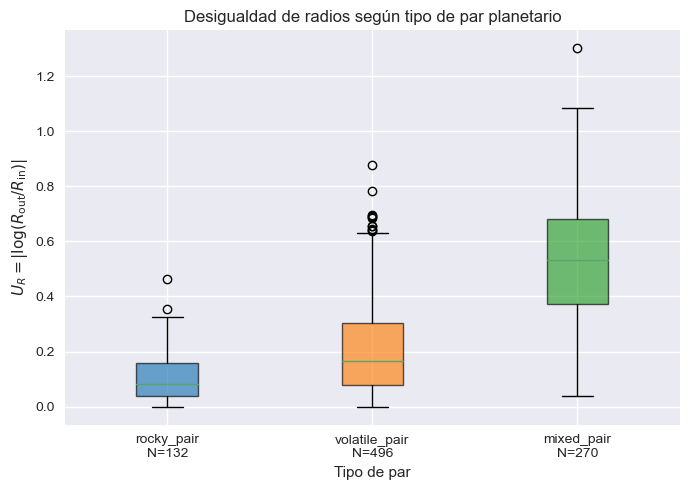

In [30]:
orden_pair_type = ["rocky_pair", "volatile_pair", "mixed_pair"]

datos_pair_type = [
    df_pares[df_pares["pair_type"] == tipo]["abs_log_radius_ratio"].dropna()
    for tipo in orden_pair_type
]

labels_pair_type = [
    f"{tipo}\nN={len(datos)}"
    for tipo, datos in zip(orden_pair_type, datos_pair_type)
]

plt.figure(figsize=(7, 5))

box = plt.boxplot(
    datos_pair_type,
    labels=labels_pair_type,
    patch_artist=True,
    showfliers=True
)

colores = ["tab:blue", "tab:orange", "tab:green"]

for patch, color in zip(box["boxes"], colores):
    patch.set_facecolor(color)
    patch.set_alpha(0.65)

plt.ylabel(r"$U_R = |\log(R_\mathrm{out}/R_\mathrm{in})|$")
plt.xlabel("Tipo de par")
plt.title("Desigualdad de radios según tipo de par planetario")

plt.tight_layout()
plt.savefig(
    "../figures/uniformidad_por_tipo_de_par.png",
    dpi=300
)

plt.show()

La desigualdad de radios entre planetas adyacentes depende fuertemente del tipo de par definido respecto al límite exploratorio de 1.6 R⊕. Los pares mixtos, formados por un planeta a cada lado de este límite, presentan los valores más altos de U_R = |log(R_out/R_in)|. En contraste, los pares rocosos son los más uniformes y los pares volátiles presentan una dispersión intermedia. Esta diferencia es significativa según Kruskal–Wallis (H = 380.69, p < 0.001) y las comparaciones post-hoc indican diferencias significativas entre los tres grupos.

El tipo de par explica una fracción importante de la desigualdad de radios, pero no elimina la asociación entre separación orbital y uniformidad planetaria.

In [31]:
tabla_comparativa_pair_type.to_csv(
    "../tables/tabla_comparativa_rocky_volatile_mixed.csv",
    index=False
)

In [32]:
resumen_radius_valley_pair_type = pd.DataFrame({
    "resultado": [
        "N por tipo de par",
        "Diferencia global en U_R",
        "Post-hoc U_R",
        "Modelo con pair_type",
        "Conclusión"
    ],
    "valor": [
        "rocky_pair = 132, volatile_pair = 496, mixed_pair = 270",
        "Kruskal-Wallis H = 380.69, p < 0.001",
        "Los tres grupos difieren significativamente; mixed_pair tiene la mayor desigualdad",
        "log_period_ratio sigue significativo: coef = 0.033, IC95% = [0.013, 0.054], p = 0.002",
        "El tipo de par explica gran parte de U_R, pero la señal spacing–uniformidad persiste"
    ]
})

resumen_radius_valley_pair_type.to_csv(
    "../tables/resumen_radius_valley_pair_type.csv",
    index=False
)

resumen_radius_valley_pair_type

,resultado,valor
0,N por tipo de par,"rocky_pair = 132, volatile_pair = 496, mixed_p..."
1,Diferencia global en U_R,"Kruskal-Wallis H = 380.69, p < 0.001"
2,Post-hoc U_R,Los tres grupos difieren significativamente; m...
3,Modelo con pair_type,log_period_ratio sigue significativo: coef = 0...
4,Conclusión,"El tipo de par explica gran parte de U_R, pero..."


Los pares planetarios más separados orbitalmente presentan mayor desigualdad de tamaños; esta señal es robusta, sobrevive a modelos controlados y no desaparece al considerar el tipo de par respecto al radius valley.

In [33]:
fraccion_outer_larger = df_pares["outer_larger"].mean()
N_outer = df_pares["outer_larger"].notna().sum()

tabla_outer_larger_global = pd.DataFrame({
    "variable": ["outer_larger"],
    "N_pares": [N_outer],
    "fraccion_outer_larger": [fraccion_outer_larger],
    "porcentaje_outer_larger": [100 * fraccion_outer_larger]
})

tabla_outer_larger_global.to_csv(
    "../tables/tabla_outer_larger_global.csv",
    index=False
)

tabla_outer_larger_global

,variable,N_pares,fraccion_outer_larger,porcentaje_outer_larger
0,outer_larger,898,0.688196,68.819599


In [34]:
df_pares_ordering = df_pares[
    df_pares["outer_larger"].notna() &
    df_pares["st_met"].notna() &
    df_pares["st_mass"].notna() &
    df_pares["log_period_ratio"].notna() &
    df_pares["pair_type"].notna()
].copy()

df_pares_ordering["met_bin"] = pd.qcut(
    df_pares_ordering["st_met"],
    q=3,
    labels=["baja_metalicidad", "media_metalicidad", "alta_metalicidad"]
)

df_pares_ordering["mass_bin"] = pd.qcut(
    df_pares_ordering["st_mass"],
    q=3,
    labels=["baja_masa", "media_masa", "alta_masa"]
)

df_pares_ordering["spacing_bin"] = pd.qcut(
    df_pares_ordering["log_period_ratio"],
    q=3,
    labels=["spacing_bajo", "spacing_medio", "spacing_alto"]
)


def resumir_outer_larger_por_grupo(df, columna_grupo):
    tabla = (
        df
        .groupby(columna_grupo, observed=True)["outer_larger"]
        .agg(
            N_pares="count",
            fraccion_outer_larger="mean"
        )
        .reset_index()
    )
    
    tabla["porcentaje_outer_larger"] = 100 * tabla["fraccion_outer_larger"]
    tabla["agrupacion"] = columna_grupo
    
    tabla = tabla.rename(columns={columna_grupo: "grupo"})
    
    return tabla[
        ["agrupacion", "grupo", "N_pares", "fraccion_outer_larger", "porcentaje_outer_larger"]
    ]


tabla_outer_larger_grupos = pd.concat(
    [
        resumir_outer_larger_por_grupo(df_pares_ordering, "met_bin"),
        resumir_outer_larger_por_grupo(df_pares_ordering, "mass_bin"),
        resumir_outer_larger_por_grupo(df_pares_ordering, "spacing_bin"),
        resumir_outer_larger_por_grupo(df_pares_ordering, "pair_type")
    ],
    ignore_index=True
)

tabla_outer_larger_grupos.to_csv(
    "../tables/tabla_outer_larger_por_grupos.csv",
    index=False
)

tabla_outer_larger_grupos.round(4)

,agrupacion,grupo,N_pares,fraccion_outer_larger,porcentaje_outer_larger
0,met_bin,baja_metalicidad,310,0.6581,65.8065
1,met_bin,media_metalicidad,291,0.7079,70.7904
2,met_bin,alta_metalicidad,297,0.7003,70.0337
3,mass_bin,baja_masa,303,0.6568,65.6766
4,mass_bin,media_masa,296,0.6959,69.5946
5,mass_bin,alta_masa,299,0.7124,71.2375
6,spacing_bin,spacing_bajo,300,0.5933,59.3333
7,spacing_bin,spacing_medio,299,0.6856,68.5619
8,spacing_bin,spacing_alto,299,0.7860,78.5953
9,pair_type,mixed_pair,270,0.8481,84.8148


In [35]:
X_ordering = df_pares_ordering[
    [
        "st_met",
        "st_mass",
        "log_period_ratio"
    ]
]

X_ordering = sm.add_constant(X_ordering)

y_ordering = df_pares_ordering["outer_larger"]

modelo_ordering = sm.Logit(y_ordering, X_ordering).fit()

modelo_ordering.summary()

Optimization terminated successfully.
         Current function value: 0.604546
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:           outer_larger   No. Observations:                  898
Model:                          Logit   Df Residuals:                      894
Method:                           MLE   Df Model:                            3
Date:                Mon, 17 Aug 2026   Pseudo R-squ.:                 0.02577
Time:                        09:43:05   Log-Likelihood:                -542.88
converged:                       True   LL-Null:                       -557.24
Covariance Type:            nonrobust   LLR p-value:                 2.566e-06
====================================================================================
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -0.2134      0.322     -0.663      0.507      -0.844       0.417
st_met               0.0962      0.445      0.216      0.829      -0.775       0.968
st_mass              0.3864      0.317      1.218      0.223      -0.235       1.008
log_period_ratio     0.7718      0.161      4.788      0.000       0.456       1.088
====================================================================================
"""

In [36]:
params_ordering = modelo_ordering.params
conf_ordering = modelo_ordering.conf_int()

tabla_or_ordering = pd.DataFrame({
    "variable": params_ordering.index,
    "coef": params_ordering.values,
    "p_value": modelo_ordering.pvalues.values,
    "odds_ratio": np.exp(params_ordering.values),
    "OR_IC95_low": np.exp(conf_ordering[0].values),
    "OR_IC95_high": np.exp(conf_ordering[1].values)
})

tabla_or_ordering.to_csv(
    "../tables/tabla_logit_size_ordering_odds_ratios.csv",
    index=False
)

tabla_or_ordering.round(4)

,variable,coef,p_value,odds_ratio,OR_IC95_low,OR_IC95_high
0,const,-0.2134,0.5071,0.8078,0.4300,1.5176
1,st_met,0.0962,0.8287,1.1010,0.4606,2.6319
2,st_mass,0.3864,0.2231,1.4717,0.7904,2.7402
3,log_period_ratio,0.7718,0.0000,2.1637,1.5776,2.9676


Se observa una tendencia global a que los planetas exteriores sean más grandes que los interiores. En la muestra de pares adyacentes, la fracción global de outer_larger es aproximadamente 0.688. Esta tendencia se intensifica con la separación orbital: la fracción de pares con R_out > R_in aumenta desde 59.3% en el tercil de menor spacing hasta 78.6% en el tercil de mayor spacing. En el modelo logístico, log(P_out/P_in) es el único predictor significativo de outer_larger (OR = 2.16, IC95% = [1.58, 2.97], p < 0.001), mientras que [Fe/H] y Mstar no muestran asociaciones significativas.


In [37]:
resumen_modelo_ordering = pd.DataFrame({
    "modelo": ["outer_larger ~ st_met + st_mass + log_period_ratio"],
    "N": [int(modelo_ordering.nobs)],
    "pseudo_R2": [modelo_ordering.prsquared],
    "LLR_p_value": [modelo_ordering.llr_pvalue],
    "AIC": [modelo_ordering.aic],
    "BIC": [modelo_ordering.bic]
})

resumen_modelo_ordering.to_csv(
    "../tables/resumen_modelo_size_ordering.csv",
    index=False
)

resumen_modelo_ordering

,modelo,N,pseudo_R2,LLR_p_value,AIC,BIC
0,outer_larger ~ st_met + st_mass + log_period_r...,898,0.025768,0.000003,1093.765062,1112.965743


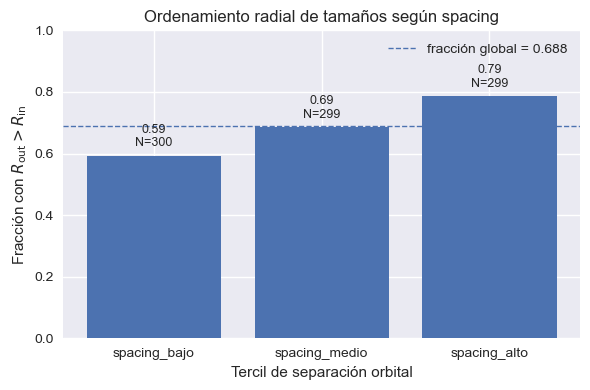

In [38]:
tabla_outer_spacing = tabla_outer_larger_grupos[
    tabla_outer_larger_grupos["agrupacion"] == "spacing_bin"
].copy()

plt.figure(figsize=(6, 4))

plt.bar(
    tabla_outer_spacing["grupo"],
    tabla_outer_spacing["fraccion_outer_larger"]
)

plt.axhline(
    fraccion_outer_larger,
    linestyle="--",
    linewidth=1,
    label=f"fracción global = {fraccion_outer_larger:.3f}"
)

plt.ylabel("Fracción con $R_\mathrm{out} > R_\mathrm{in}$")
plt.xlabel("Tercil de separación orbital")
plt.title("Ordenamiento radial de tamaños según spacing")
plt.ylim(0, 1)

for i, row in tabla_outer_spacing.iterrows():
    plt.text(
        row["grupo"],
        row["fraccion_outer_larger"] + 0.02,
        f"{row['fraccion_outer_larger']:.2f}\nN={int(row['N_pares'])}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.legend()
plt.tight_layout()
plt.savefig(
    "../figures/outer_larger_fraction_by_spacing.png",
    dpi=300
)

plt.show()

In [39]:
df_interaccion = df_pares[
    df_pares["abs_log_radius_ratio"].notna() &
    df_pares["log_period_ratio"].notna() &
    df_pares["st_met"].notna() &
    df_pares["st_mass"].notna() &
    df_pares["pair_median_radius"].notna()
].copy()

modelo_interaccion = smf.ols(
    "abs_log_radius_ratio ~ log_period_ratio * st_met + st_mass + pair_median_radius",
    data=df_interaccion
).fit()

modelo_interaccion.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                             OLS Regression Results                             
================================================================================
Dep. Variable:     abs_log_radius_ratio   R-squared:                       0.060
Model:                              OLS   Adj. R-squared:                  0.055
Method:                   Least Squares   F-statistic:                     11.35
Date:                  Mon, 17 Aug 2026   Prob (F-statistic):           1.24e-10
Time:                          09:49:32   Log-Likelihood:                 47.031
No. Observations:                   898   AIC:                            -82.06
Df Residuals:                       892   BIC:                            -53.26
Df Model:                             5                                         
Covariance Type:              nonrobust                                         
===========================================================================================
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                   0.2377      0.040      6.001      0.000       0.160       0.316
log_period_ratio            0.0848      0.014      6.215      0.000       0.058       0.112
st_met                      0.1687      0.088      1.916      0.056      -0.004       0.342
log_period_ratio:st_met    -0.0308      0.080     -0.387      0.699      -0.187       0.125
st_mass                     0.0565      0.035      1.623      0.105      -0.012       0.125
pair_median_radius         -0.0350      0.014     -2.528      0.012      -0.062      -0.008
==============================================================================
Omnibus:                      102.360   Durbin-Watson:                   2.072
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              135.811
Skew:                           0.917   Prob(JB):                     3.23e-30
Kurtosis:                       3.516   Cond. No.                         40.4
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [40]:
tabla_modelo_interaccion = pd.DataFrame({
    "variable": modelo_interaccion.params.index,
    "coef": modelo_interaccion.params.values,
    "std_err": modelo_interaccion.bse.values,
    "t": modelo_interaccion.tvalues.values,
    "p_value": modelo_interaccion.pvalues.values,
    "IC95_low": modelo_interaccion.conf_int()[0].values,
    "IC95_high": modelo_interaccion.conf_int()[1].values
})

tabla_modelo_interaccion.to_csv(
    "../tables/modelo_interaccion_metalicidad_spacing.csv",
    index=False
)

tabla_modelo_interaccion

,variable,coef,std_err,t,p_value,IC95_low,IC95_high
0,Intercept,0.237741,0.039620,6.000503,2.857546e-09,0.159981,0.315501
1,log_period_ratio,0.084844,0.013652,6.214512,7.893113e-10,0.058049,0.111638
2,st_met,0.168714,0.088071,1.915660,5.572789e-02,-0.004136,0.341564
3,log_period_ratio:st_met,-0.030786,0.079562,-0.386945,6.988893e-01,-0.186936,0.125364
4,st_mass,0.056537,0.034845,1.622530,1.050433e-01,-0.011851,0.124924
5,pair_median_radius,-0.034979,0.013837,-2.528002,1.164298e-02,-0.062135,-0.007823


In [41]:
resumen_modelo_interaccion = pd.DataFrame({
    "modelo": ["U_R ~ log_period_ratio * st_met + st_mass + pair_median_radius"],
    "N": [int(modelo_interaccion.nobs)],
    "R2": [modelo_interaccion.rsquared],
    "R2_ajustado": [modelo_interaccion.rsquared_adj],
    "F_p_value": [modelo_interaccion.f_pvalue],
    "AIC": [modelo_interaccion.aic],
    "BIC": [modelo_interaccion.bic],
    "interaccion_coef": [modelo_interaccion.params["log_period_ratio:st_met"]],
    "interaccion_p": [modelo_interaccion.pvalues["log_period_ratio:st_met"]]
})

resumen_modelo_interaccion.to_csv(
    "../tables/resumen_modelo_interaccion_metalicidad_spacing.csv",
    index=False
)

resumen_modelo_interaccion

,modelo,N,R2,R2_ajustado,F_p_value,AIC,BIC,interaccion_coef,interaccion_p
0,U_R ~ log_period_ratio * st_met + st_mass + pa...,898,0.059806,0.054536,1.244586e-10,-82.061,-53.25998,-0.030786,0.698889


No se encontró evidencia de que la metalicidad estelar modifique la relación entre separación orbital y desigualdad de tamaños. El término de interacción log(P_out/P_in) × [Fe/H] no fue significativo (coef = -0.031, IC95% = [-0.187, 0.125], p = 0.699). La asociación positiva entre log(P_out/P_in) y U_R permanece significativa, lo que sugiere que la relación spacing–uniformidad es similar a lo largo del rango de metalicidades considerado.
